In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 711, in start
    self.io_loop.start()
  

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 711, in start
    self.io_loop.start()
  

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 711, in start
    self.io_loop.start()
  

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\lt0828\AppData\Local\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 711, in start
    self.io_loop.start()
  

AttributeError: _ARRAY_API not found

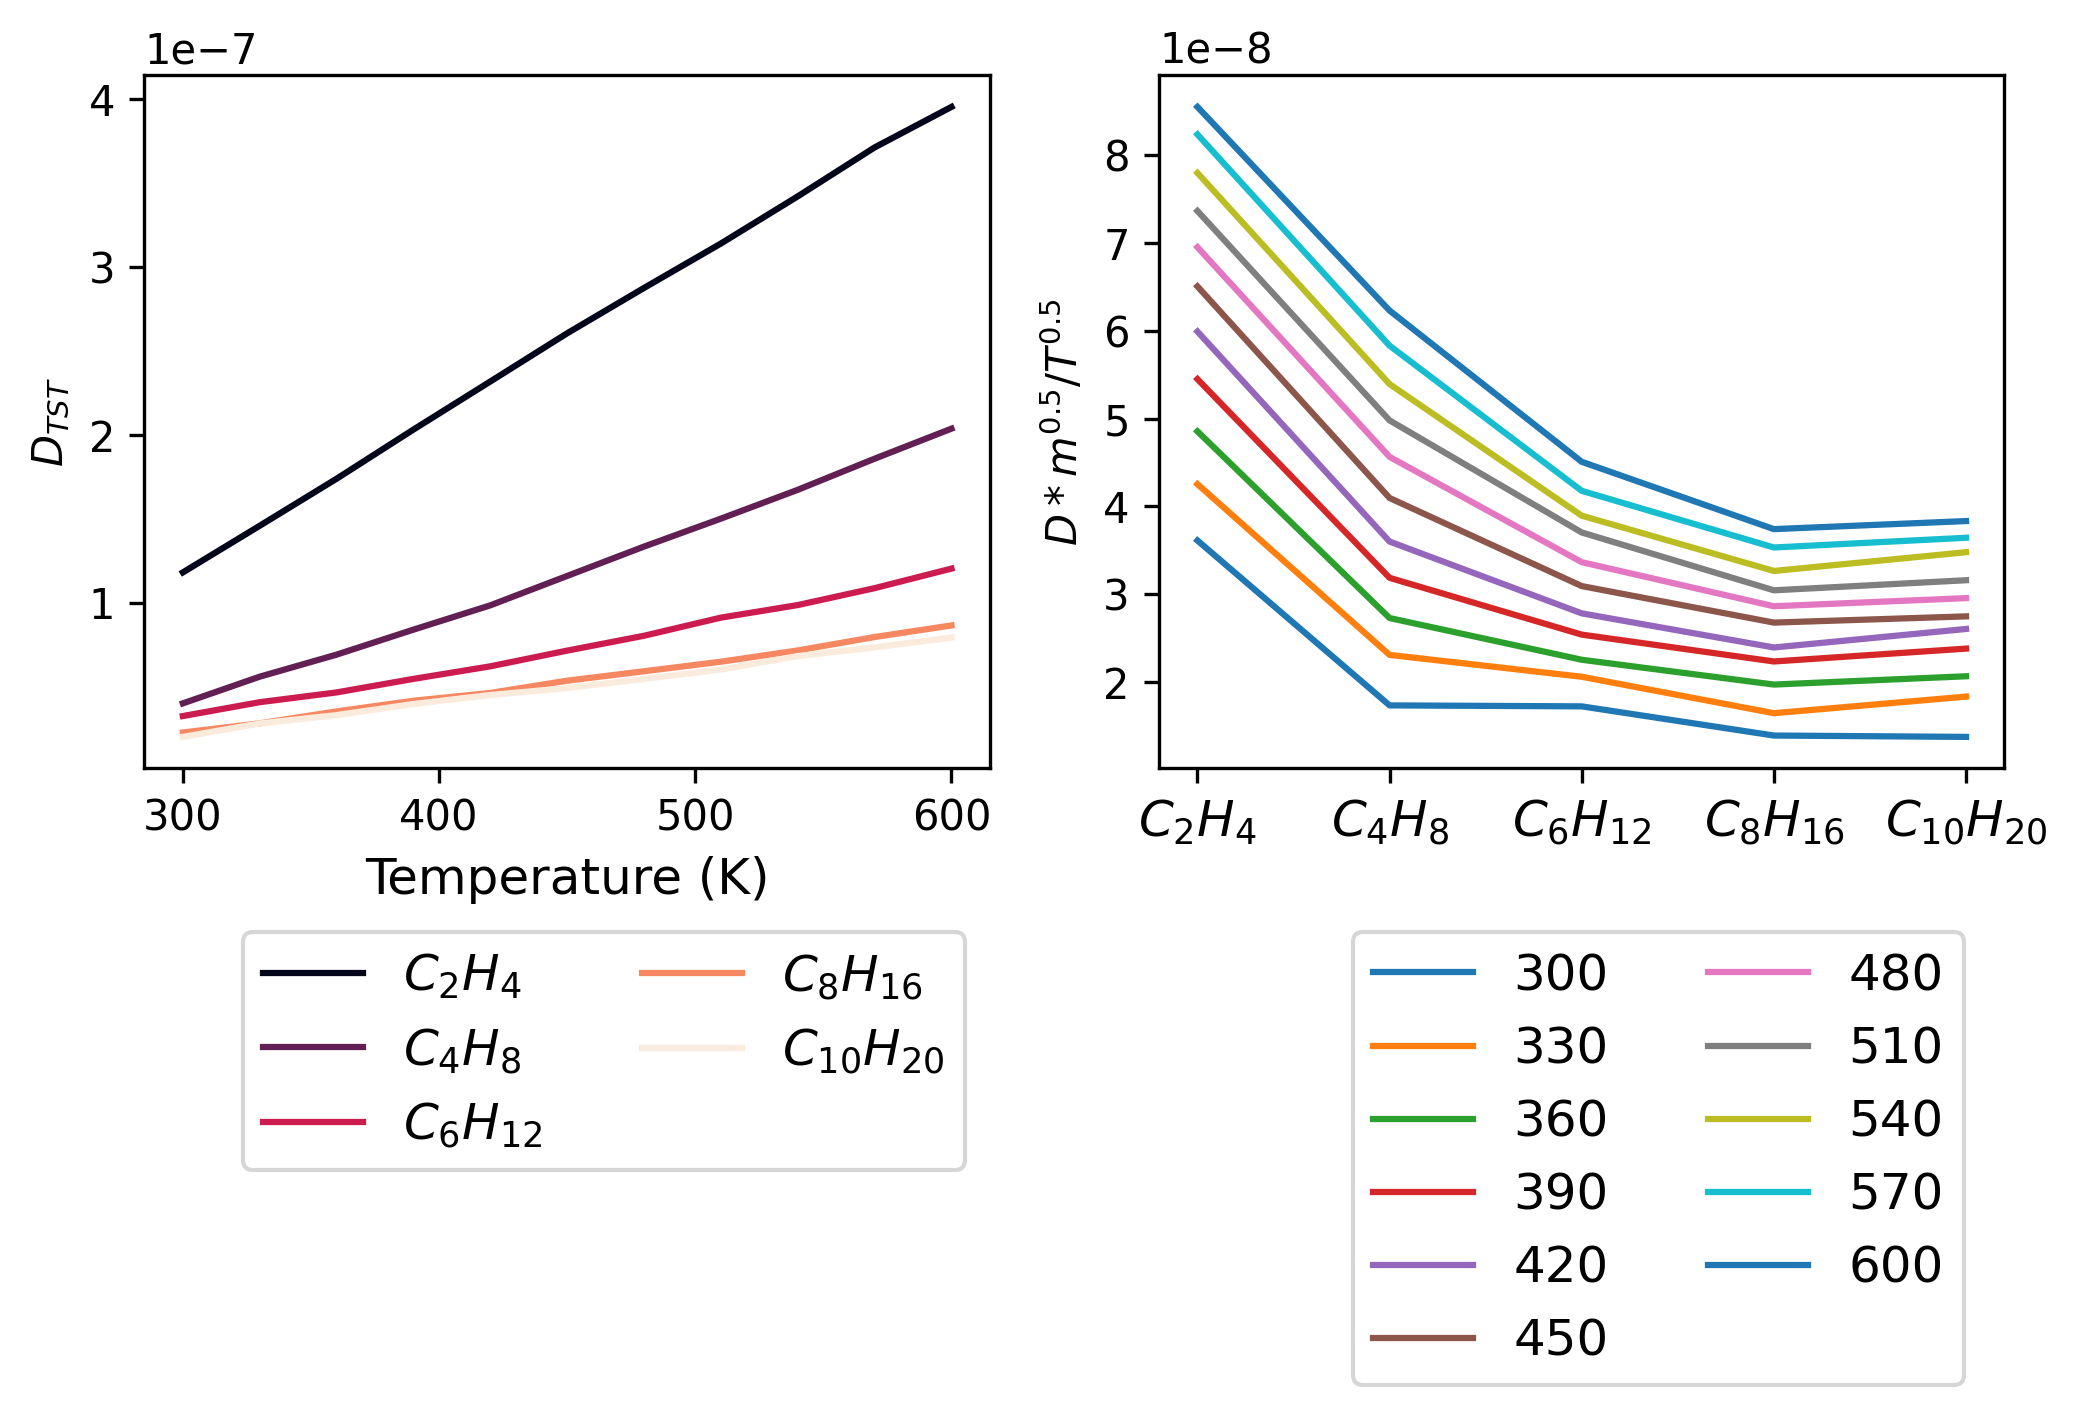

In [28]:
data = pd.read_pickle('../data/diffusion/diffusion_tst_datasetV2.pkl')
data['D_TST'] = data['D'] 

def mass_calc(n):
    """
    Calculate the mass of a molecule based on the number of atoms.
    """
    m = 1.008 * 2 * n + 12.01 * n
    return m

data['D_norm'] = data['D'] / data['temperature'] ** 0.5 * mass_calc(data['n']) ** 0.5

fig, axs = plt.subplots(1, 2, figsize=(8, 3), dpi=300)
sns.lineplot(x='temperature', y='D_TST', hue='n', data=data, palette='rocket', ax=axs[0])
sns.lineplot(x='n', y='D_norm', hue='temperature', data=data.query('n <= 10'), palette='tab10', ax=axs[1])
axs[1].set_ylabel(r'$D * m^{0.5}/ T^{0.5}$')
axs[0].set_ylabel(r'$D_{TST}$')
axs[1].set_xticks(list(range(2, 11, 2)), [f'$C_{{{n}}}H_{{{2*n}}}$' for n in range(2, 11, 2)], fontsize=12)
handles, labels = axs[0].get_legend_handles_labels()
lables = [f'$C_{{{n}}}H_{{{2*n}}}$' for n in range(2, 11, 2)]
axs[0].legend(handles, lables, title='', fontsize=12,
            ncol=2, bbox_to_anchor=(1., -0.2),)
axs[0].set_xlabel('Temperature (K)', fontsize=12)
axs[1].set_xlabel('')
handles, labels = axs[1].get_legend_handles_labels()
axs[1].legend(handles, labels, title='', fontsize=12,   
            ncol=2, bbox_to_anchor=(.2, -0.2), loc='upper left')

box = axs[1].get_position()

It is not linear from sqrt(m) ... but as a placeholder it will be okay.

In [56]:
import joblib
from kinetic_model.constants.diffusion import DiffusionLinear

# 2) Fit & save
diff_model = DiffusionLinear()
diff_model.fit(data, D_col='D_TST')
joblib.dump(diff_model, '../data/processed/diffusion_model_08072025.pkl')

['../data/processed/diffusion_model_08072025.pkl']

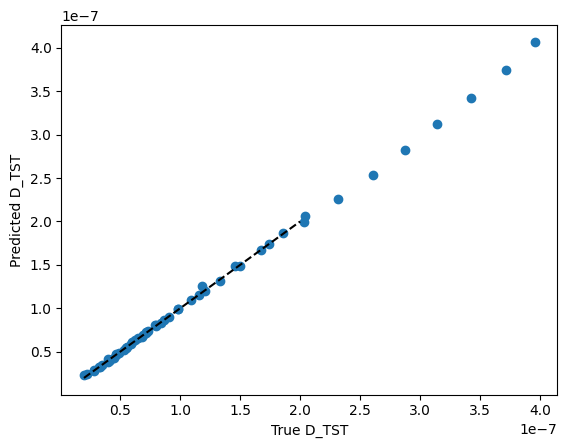

In [57]:
# 3) Later: load & predict
diff_loaded = joblib.load('../data/processed/diffusion_model_08072025.pkl')

y_pred = diff_loaded.predict(data[['temperature', 'n']])
y_true = data['D_TST'].to_numpy()
# 4) Plot
plt.scatter(y_true, y_pred)
plt.xlabel('True D_TST')
plt.ylabel('Predicted D_TST')
plt.plot([2e-8, 2e-7], [2e-8, 2e-7], 'k--')

In [20]:
from kinetic_model.constants.diffusion import DiffusionLinearExtrapPlaceHolder


diff_model_extrap = DiffusionLinearExtrapPlaceHolder()
diff_model_extrap.fit(data, D_col='D_TST')
joblib.dump(diff_model_extrap, '../data/processed/diffusion_extrap_place_holder_model.pkl')
model = joblib.load('../data/processed/diffusion_extrap_place_holder_model.pkl')
y_pred_extrap = model.predict(pd.DataFrame({'n': [2, 4, 6, 8, 10, 12], 'temperature': [300, 320, 301, 500, 100, 300]}))
y_pred_extrap

array([1.26225909e-07, 5.07443613e-08, 3.28163345e-08, 6.32792274e-08,
       9.26861942e-11, 3.35152383e-08])